# 04. Single-Run Diagnosis & Emitter Mechanics

This diagnostic notebook performs an in-depth, single-run evaluation for any completed optimization run in `results/benchmarks/` or `results/`.

### Diagnostics Computed:
1. **Oracle Budget & Validity**: Total proposals, valid SMILES, duplicates, and charged oracle calls.
2. **Novel Hits**: Unique molecules with $P(\text{active}) > 0.6$, **strictly filtering out all 115k reference training molecules**.
3. **Scaffold Diversity**: Unique exact and generic Bemis-Murcko frameworks.
4. **Archive Dynamics**: Cumulative coverage and QD Score trajectory over generations.
5. **Top Molecule Depiction**: High-resolution 2D RDKit structures of the run's best novel discoveries.


In [1]:
from __future__ import annotations

import io
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem.Scaffolds import MurckoScaffold

ROOT = Path.cwd()
while not (ROOT / "chemistry").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from chemistry.scaffolds import generic_scaffold_hash

# Strict style configuration
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
})

def style_axes(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#222222")
    ax.spines["bottom"].set_color("#222222")
    ax.spines["left"].set_linewidth(1.1)
    ax.spines["bottom"].set_linewidth(1.1)


## 1 — Select Run Directory to Diagnose

Edit `RUN_DIR` below to point to any run:


In [2]:
# Change this path to inspect any run:
RUN_DIR = ROOT / "results" / "benchmarks" / "cma_me_imp_mu_thresh_seed1"
assert RUN_DIR.is_dir(), f"Run directory {RUN_DIR} not found!"

print(f"Diagnosing run: {RUN_DIR.name}")


Diagnosing run: cma_me_imp_mu_thresh_seed1


## 2 — Load Evaluations & Strictly Filter Training Molecules


In [3]:
# Load cached canonical training molecules
train_cache_p = ROOT / "notebooks" / "cache" / "06_benchmark_analysis" / "training_canon_smiles.pkl"
if train_cache_p.exists():
    with open(train_cache_p, "rb") as f:
        train_canon = pickle.load(f)["all"]
else:
    df_tr = pd.read_csv(ROOT / "data" / "predictor" / "predictor_training_data.csv")
    train_canon = {Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in df_tr["SMILES"] if Chem.MolFromSmiles(s) is not None}

df_evals = pd.read_csv(
    RUN_DIR / "all_evaluations.csv",
    usecols=["canonical_smiles", "oracle_called", "p_active", "valid", "duplicate"],
)

charged = df_evals[df_evals["oracle_called"].astype(str).str.lower().eq("true")].dropna(subset=["p_active"]).copy()
charged["canonical_smiles"] = charged["canonical_smiles"].astype(str)
charged_unique = charged.drop_duplicates(subset=["canonical_smiles"]).reset_index(drop=True)

# Strict novel hits
novel_hits = charged_unique[
    (charged_unique["p_active"] > 0.6) & (~charged_unique["canonical_smiles"].isin(train_canon))
].sort_values("p_active", ascending=False).reset_index(drop=True)

gen_scaffolds = [generic_scaffold_hash(s) for s in novel_hits["canonical_smiles"]]
novel_hits["generic_scaffold"] = gen_scaffolds

print(f"Total proposals:          {len(df_evals):,}")
print(f"Valid molecules:          {df_evals['valid'].sum():,}")
print(f"Duplicates:               {df_evals['duplicate'].sum():,}")
print(f"Charged unique oracle:    {len(charged_unique):,}")
print(f"Strict novel hits (>0.6): {len(novel_hits):,}")
print(f"Unique generic scaffolds: {len(set(gen_scaffolds)):,}")


Total proposals:          111,240
Valid molecules:          111,239
Duplicates:               11,104
Charged unique oracle:    100,135
Strict novel hits (>0.6): 9,503
Unique generic scaffolds: 1,253


## 3 — Search Trajectories & Behavior Archive Growth


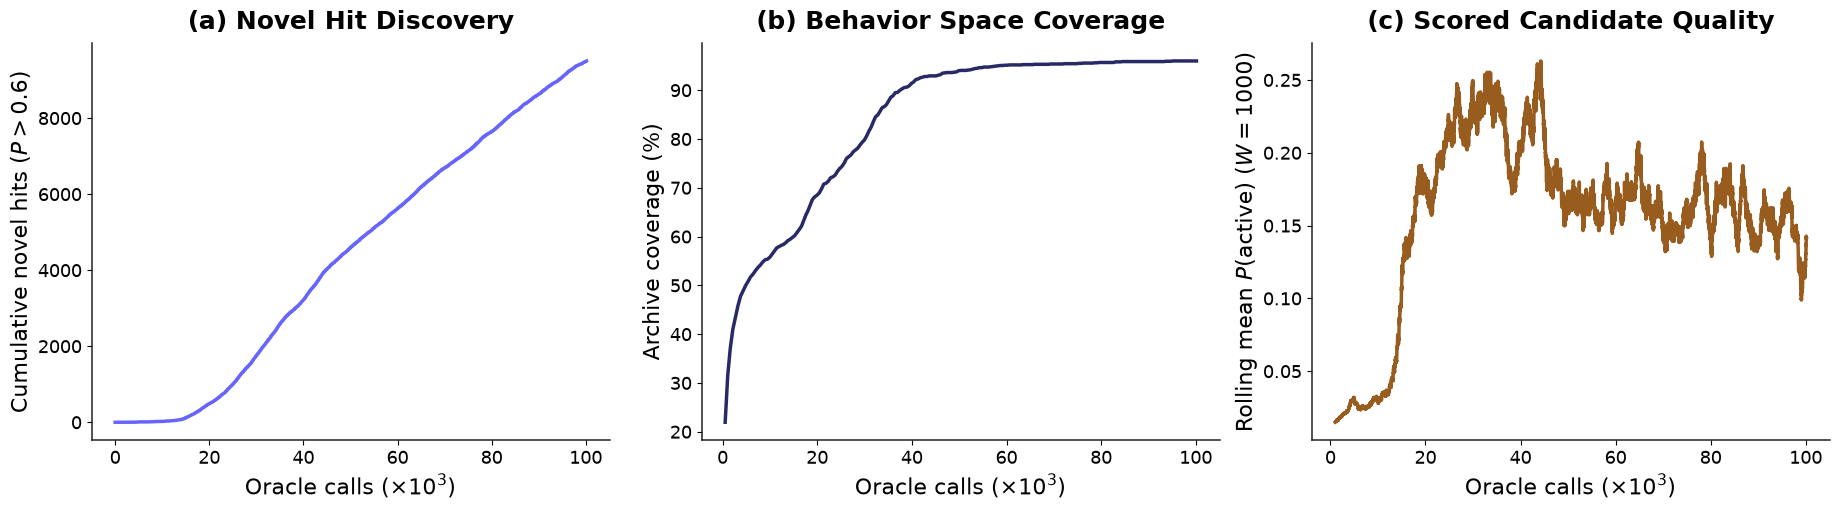

In [4]:
curve_df = pd.read_csv(RUN_DIR / "curve.csv")

fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.2))

# (a) Novel Hits over Evaluations
ax = axes[0]
style_axes(ax)
eval_idx = np.arange(1, len(charged_unique) + 1)
cum_hits = np.cumsum(
    (charged_unique["p_active"] > 0.6) & (~charged_unique["canonical_smiles"].isin(train_canon))
)
ax.plot(eval_idx / 1e3, cum_hits, color="#6666FF", lw=2.5)
ax.set_xlabel("Oracle calls ($\\times 10^3$)")
ax.set_ylabel("Cumulative novel hits ($P > 0.6$)")
ax.set_title("(a) Novel Hit Discovery", pad=10)

# (b) Result Archive Coverage
ax = axes[1]
style_axes(ax)
ax.plot(curve_df["oracle_calls"] / 1e3, curve_df["result_coverage"] * 100.0, color="#292966", lw=2.5)
ax.set_xlabel("Oracle calls ($\\times 10^3$)")
ax.set_ylabel("Archive coverage (%)")
ax.set_title("(b) Behavior Space Coverage", pad=10)

# (c) Rolling Mean P(active)
ax = axes[2]
style_axes(ax)
p_vals = charged_unique["p_active"].to_numpy()
w = 1000
if len(p_vals) >= w:
    csum = np.concatenate([[0.0], np.cumsum(p_vals)])
    roll_mean = (csum[w:] - csum[:-w]) / float(w)
    ax.plot(eval_idx[w - 1:] / 1e3, roll_mean, color="#995C1F", lw=2.5)
ax.set_xlabel("Oracle calls ($\\times 10^3$)")
ax.set_ylabel("Rolling mean $P(\\mathrm{active})$ ($W=1000$)")
ax.set_title("(c) Scored Candidate Quality", pad=10)

fig.tight_layout()
plt.show()


## 4 — 2D Molecule Depiction of Top Novel Discoveries


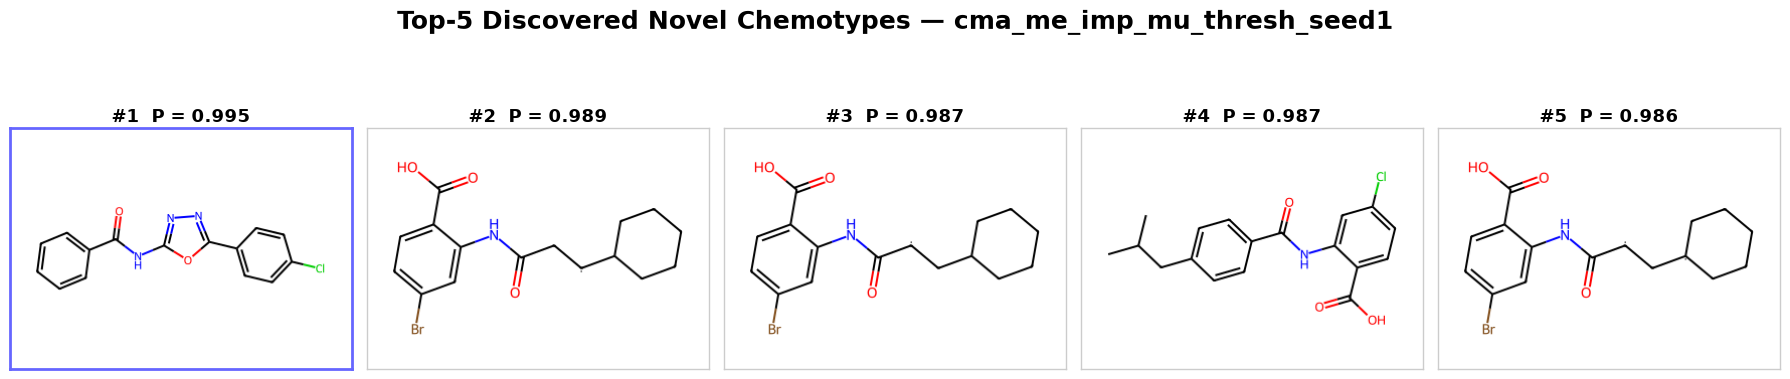

In [5]:
def render_mol_image(smi: str, width: int = 340, height: int = 240) -> np.ndarray:
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return np.ones((height, width, 3), dtype=np.uint8) * 255
    rdDepictor.Compute2DCoords(mol)
    drawer = rdMolDraw2D.MolDraw2DCairo(width, height)
    opts = drawer.drawOptions()
    opts.bondLineWidth = 2.0
    opts.padding = 0.08
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    png = drawer.GetDrawingText()
    return np.asarray(Image.open(io.BytesIO(png)).convert("RGB"))

# Top-5 distinct generic scaffolds
top_div = novel_hits.drop_duplicates("generic_scaffold").head(5).reset_index(drop=True)

fig, axes = plt.subplots(1, 5, figsize=(18, 4.2))
fig.suptitle(f"Top-5 Discovered Novel Chemotypes — {RUN_DIR.name}", fontsize=18, fontweight="bold", y=1.02)

for i in range(5):
    ax = axes[i]
    ax.set_xticks([])
    ax.set_yticks([])
    if i < len(top_div):
        row = top_div.iloc[i]
        ax.imshow(render_mol_image(row["canonical_smiles"]))
        ax.set_title(f"#{i+1}  P = {row['p_active']:.3f}", fontsize=13, fontweight="bold", pad=4)
        for sp in ax.spines.values():
            sp.set_visible(True)
            sp.set_color("#6666FF" if i == 0 else "#CCCCCC")
            sp.set_linewidth(2.0 if i == 0 else 1.0)

fig.tight_layout()
plt.show()
